# 1. Sharing a ride

Examples of
- how a real situation becomes a **bargaining problem** $(S, d)$: the possible agreements and the disagreement point;
- how the **Nash solution** picks one agreement, and why it is the equal split here;
- how an **outside option** (a better alternative if the talks fail) gives bargaining power.

This book follows the first slides of the lecture (*The bargaining problem*, *Nash bargaining solution*).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from bargain import *

---
## 1.1 Share a ride

Alice drives every morning from Lille to Valenciennes. Bob needs to make the same trip.

| Assumption | Value |
|---|---|
| Alice drives anyway | her fuel and tolls are paid whatever happens |
| picking Bob up | a small detour: **4 EUR** of extra fuel (`DETOUR`) |
| Bob's alternative | the train: **18 EUR** (`TRAIN`) |
| the deal | Bob pays a **contribution** $c$ to Alice |

We count only what each one **gains thanks to the deal**:

- Alice (agent 1) receives $c$ and pays the detour: $u_1 = c - 4$;
- Bob (agent 2) pays $c$ instead of the train ticket: $u_2 = 18 - c$.

If they do not agree, Alice drives alone and Bob takes the train: nobody gains anything, so $d = (0, 0)$.

In [3]:
DETOUR = 4      # (minimal threshold for driver) EUR: extra fuel for the driver to pick up the passenger
TRAIN = 18      # (maximal threshold for passenger) EUR: the passenger's train ticket (his alternative)

### return a array [driver, passenger]: the gains of the driver and the passenger for a given contribution between start and end of the negotiation
def gains(contribution, mini, maxi):
    return np.array([contribution - mini, maxi - contribution])

#note: a better definition could be np.array([min(0, contribution - mini), min(0, maxi - contribution)])

#gain if driver contributes 4 EUR, 11 EUR, or 18 EUR
for c in {4, 11, 18}:
    gains_array = gains(c, DETOUR, TRAIN)
    print(f"contribution {c} EUR  -> gains for driver = {gains_array[0]}, gains for passenger = {gains_array[1]}")

contribution 18 EUR  -> gains for driver = 14, gains for passenger = 0
contribution 11 EUR  -> gains for driver = 7, gains for passenger = 7
contribution 4 EUR  -> gains for driver = 0, gains for passenger = 14


With $c = 4$, Alice only covers her detour; with $c = 18$, Bob saves nothing.  
Any contribution between 4 and 18 EUR is better than no deal **for both**:  the ride creates a **surplus** of $18 - 4 = 14$ EUR to be shared.

-- -- --

**Exercise 1**.  
- Take 1401 *(100x14+1)* contributions between 4 and 18 EUR (`np.linspace`), 
- Compute the gains with the function`gains`, 
- Add them in a array `S` (ex. `S=[[0,14], [1,13], ...., [14,0]]`)
- And draw $S$ with `plot_problem(points, line=True)`. 
- Check that $u_1 + u_2 = 14$ for every agreement.

In [ ]:
#example of 
print(np.linspace(1, 2, 5))

array([1.  , 1.25, 1.5 , 1.75, 2.  ])

In [7]:
table = np.array([[4, 14], [11, 7], [18, 0]])
print(table.sum(axis=1))  # sum of each row

[18 18 18]


In [13]:
vals_1 = [26,26,26,26,26,26,26,26,26,26,26,26,26,27,26,27,26,26,26,26]
print(vals_1)
#get the unique values in the array
unique_vals_1 = np.unique(vals_1)
print(unique_vals_1)
#test if all values in the array are equals
print("vals_1 contain only one unique value:", len(unique_vals_1) == 1)

vals_2 = [26,26,26,26,26,26,26,26,26,26,26,26,26,26,26,26,26,26,26,26]
print(vals_2)
#get the unique values in the array
unique_vals_2 = np.unique(vals_2)
print(unique_vals_2)
#test if all values in the array are equals
print("vals_2 contain only one unique value:", len(unique_vals_2) == 1)


[26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 27, 26, 27, 26, 26, 26, 26]
[26 27]
vals_1 contain only one unique value: False
[26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26]
[26]
vals_2 contain only one unique value: True


In [ ]:
#your code 

u1 + u2 is always [14.]


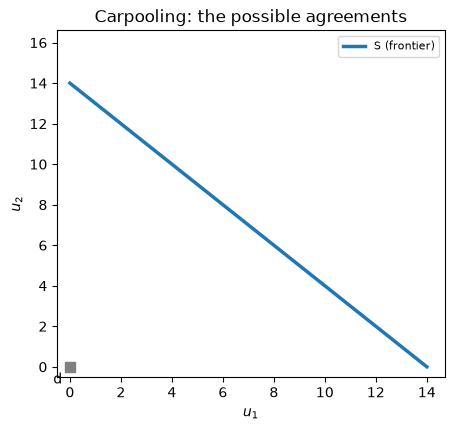

In [ ]:
plot_problem(S, line=True, title="Carpooling: the possible agreements");

**Reading.** 
- $S$ is a segment from $(0, 14)$ (Bob keeps everything) to $(14, 0)$ (Alice keeps everything). 
- The question is: **choose a point of this segment!**

---


## 1.2 The Nash solution

Nash (1950) proposes to choose the agreement that maximises the **product of the gains** over the disagreement point:

$$(u_1^*, u_2^*) = \arg\max_{(u_1,u_2) \in S,\ u \geq d}\ (u_1 - d_1)\,(u_2 - d_2)$$

  - `nash_solution(points, d)` does exactly this on a list of points. 
  - `plot_problem(..., nash_curve=True)` also draws the points having the **same product** as the solution (a level curve, not a choice): every other agreement lies below it.

Nash solution: [7. 7.]


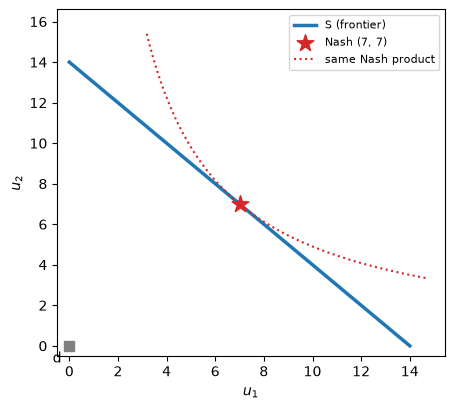

In [16]:
nash = nash_solution(S)
print("Nash solution:", nash)
plot_problem(S, solutions={"Nash": nash}, nash_curve=True, line=True);

---
**Exercise 2** *(≈ 3 lines)*. 
- Which **contribution** $c^*$ corresponds to the Nash solution? 
- Compute the product $u_1 u_2$ for all the agreements of `S`, 
- find the index of the maximum (`np.argmax`) and read the contribution.

In [17]:
# example of np.argmax
arr = np.array([1, 3, 2, 5, 4])
print("Array:", arr)
print("Index of the maximum value:", np.argmax(arr))

Array: [1 3 2 5 4]
Index of the maximum value: 3


In [ ]:
# Exercise 2: your code here

c* = 11.00 EUR, gains = [7. 7.]


**Reading.** Bob pays 11 EUR: each one gains 7 EUR, half of the surplus.

This is the **symmetry** axiom at work!
  - The problem is symmetric: $d_1 = d_2 = 0$, and if $(u_1, u_2)$ is possible, $(u_2, u_1)$ is possible too (both lie on $u_1 + u_2 = 14$). 
  - Nothing distinguishes Alice from Bob, so the solution must give them the same gain.

---

## 1.3 An outside option

Now Carla, a colleague of Alice, can also ride with her.  
She lives on Alice's way (no detour) and would pay 8 EUR.  
If Bob refuses, Alice takes Carla and gains 8 EUR: the disagreement point between Alice and Bob becomes $d = (8, 0)$. (Alice's car has one free seat only.)

**Exercise 3** . 
 - Compute the Nash solution with, now, $d = (8, 0)$ and the corresponding contribution of Bob. 
 - Which agreements are no longer acceptable?

In [21]:
#you can use the function of bargain library : acceptable(the_points, d=(d1, d2)))
# that returns a array of acceptable points , where for each point point[0] >= d[0] and point[1] >= d[1]
the_points = [[1,2], [3,4], [0,6], [7,5], [2,7], [10,6]]
acceptable_points = acceptable(the_points, d=(2, 6))
print("in the_points:", the_points)
print(" with a threshold d=(2, 6), the acceptable points are those where point[0] >= 2 and point[1] >= 6")
print("Acceptable points:", acceptable_points)

in the_points: [[1, 2], [3, 4], [0, 6], [7, 5], [2, 7], [10, 6]]
 with a threshold d=(2, 6), the acceptable points are those where point[0] >= 2 and point[1] >= 6
Acceptable points: [[ 2.  7.]
 [10.  6.]]


In [8]:
# Exercise 3: your code here

Nash solution with d = (8, 0): [11.  3.] -> Bob pays 15.0 EUR


acceptable contributions, from 12.00€ to : 18.00€


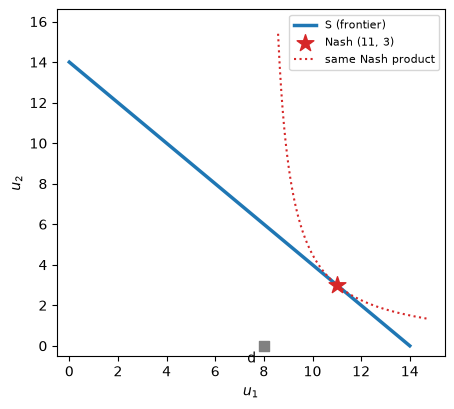

**Reading.**
 - Bob now pays 15 EUR. 
 - The agreements where Alice gains less than 8 EUR ($c < 12$) are gone: she would rather take Carla. 
 - What remains to be shared is $14 - 8 = 6$ EUR, split equally **above** $d$: Alice $8 + 3$, Bob $3$.

---
## 1.4 When the train price changes

**Exercise 4**.   
For train prices from 6 to 30 EUR (back to $d = (0, 0)$, no Carla), compute the Nash contribution $c^*$ and plot it against the train price.   

In [ ]:
# Exercise 4: your code here


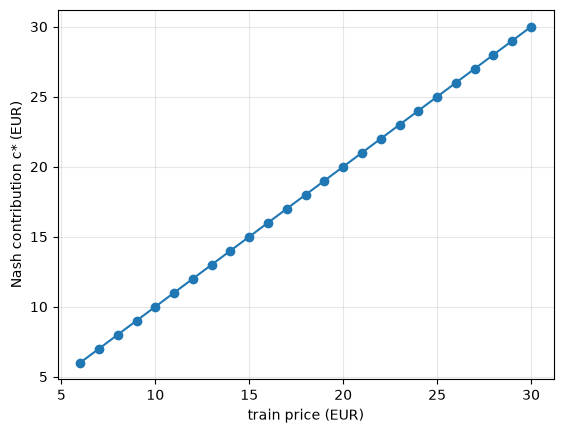

In [ ]:
#if c_star the array of Nash contributions for each train price in trains
plt.plot(trains, c_star, "o-")
plt.xlabel("train price (EUR)"); plt.ylabel("Nash contribution c* (EUR)"); plt.grid(alpha=.3); plt.show()

**Reading.**  
- $c^* = \frac{4 + \text{train}}{2}$: every euro added to the train ticket raises Bob's contribution by 50 cents. 
- Bob's alternative sets his bargaining power: if public transport gets more expensive, carpool passengers pay more too.

---

## 1.5 Changing the units does not change the deal

The **scale invariance** axiom says that measuring a utility in other units ($a\,u_i + b$, $a > 0$) must not change the agreement.

**Exercise 5** .   
Bob counts in cents: replace $u_2$ by $100\,u_2$ in `S` and compute the Nash solution again.  
Is the contribution the same?

In [12]:
# Exercise 5: your code here

In [ ]:
S_cents = S * np.array([1, 100])


contribution: 11.00 EUR (same as before)


**Reading.** The product is multiplied by 100 for **every** agreement, so the maximum is reached at the same contribution. This is why the Nash solution compares gains **without** having to say that one euro is worth the same to Alice and to Bob.

## Key points

| Notion | In the carpool |
|---|---|
| agreements $S$ | contributions from 4 to 18 EUR, i.e. the segment $u_1 + u_2 = 14$ |
| disagreement point $d$ | $(0,0)$: Alice alone, Bob by train; $(8,0)$ with Carla |
| Nash solution | maximise $(u_1-d_1)(u_2-d_2)$: equal split of the surplus **above $d$** |
| symmetry | same situation for both $\Rightarrow$ same gain (11 EUR) |
| outside option | Carla gives Alice power: Bob pays 15 EUR |
| scale invariance | the units of each utility do not matter |